In [1]:
# Import Libraries

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from keras import layers
from keras.datasets import fashion_mnist
from keras.models import Sequential
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Importing Data

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
# to Black-White picture

X_train = X_train.reshape(-1, 28, 28, 1) / 255
X_test = X_test.reshape(-1, 28, 28, 1) / 255

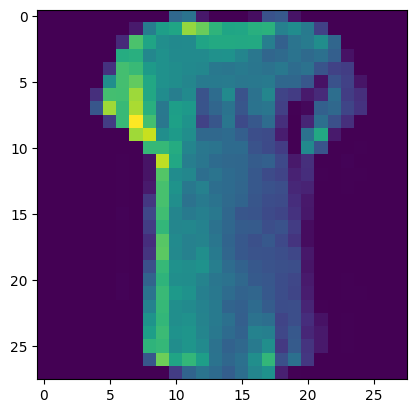

In [5]:
plt.imshow(X_train[600])

In [6]:
# Model Training

cnn_model = Sequential(
    [
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3)),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3)),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [7]:
cnn_model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [8]:
# Model Training
# For EPOCHS = 10 and BATCH_SIZE = 64

cnn_model.fit(
    X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7560 - loss: 0.6594 - val_accuracy: 0.8177 - val_loss: 0.4878
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8468 - loss: 0.4171 - val_accuracy: 0.8605 - val_loss: 0.3887
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8704 - loss: 0.3509 - val_accuracy: 0.8682 - val_loss: 0.3588
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8850 - loss: 0.3139 - val_accuracy: 0.8781 - val_loss: 0.3310
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8964 - loss: 0.2832 - val_accuracy: 0.8867 - val_loss: 0.3107
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9039 - loss: 0.2603 - val_accuracy: 0.8826 - val_loss: 0.3229
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9100 - loss: 0.2418 - val_accuracy: 0.8915 - val_loss: 0.3184
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9170 - loss: 0.2240 - val_accuracy: 0.

In [9]:
# Evaluate the model on the test set

test_loss, test_accuracy = cnn_model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 946us/step - accuracy: 0.8969 - loss: 0.3014
Test Loss: 0.3014
Test Accuracy: 0.8969


In [10]:
# Generate predictions and plot confusion matrix

y_pred = np.argmax(cnn_model.predict(X_test), axis=1)
cm = confusion_matrix(y_test, y_pred)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


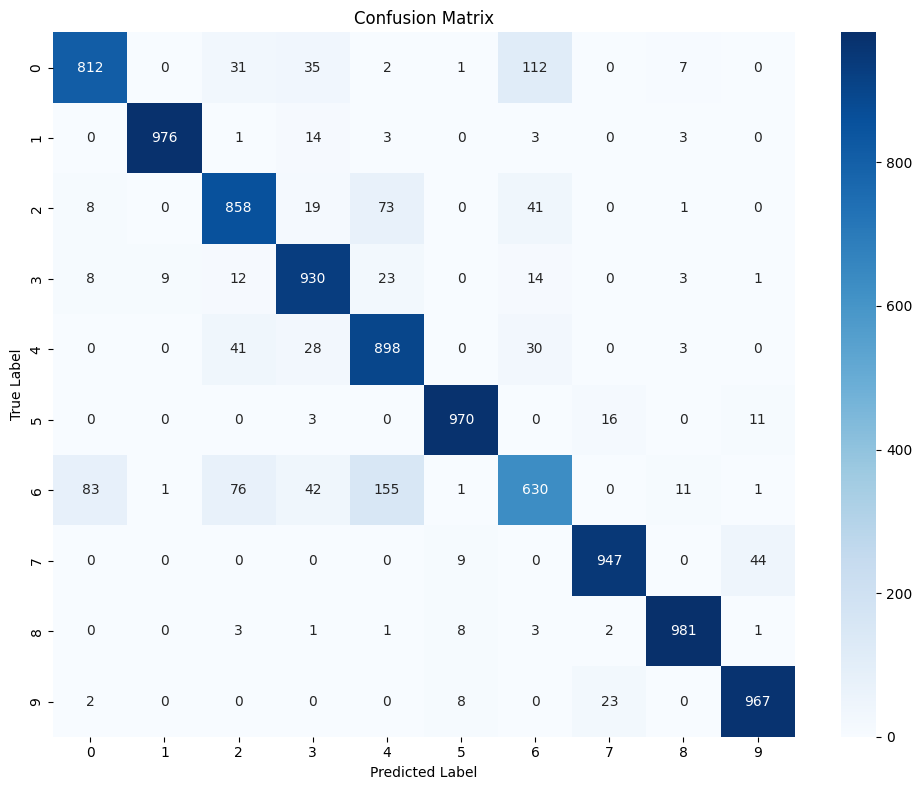

In [11]:
# Plot the confusion matrix as a heatmap

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10)
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
# Print classification report for detailed per-class metrics

print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1000
           1       0.99      0.98      0.98      1000
           2       0.84      0.86      0.85      1000
           3       0.87      0.93      0.90      1000
           4       0.78      0.90      0.83      1000
           5       0.97      0.97      0.97      1000
           6       0.76      0.63      0.69      1000
           7       0.96      0.95      0.95      1000
           8       0.97      0.98      0.98      1000
           9       0.94      0.97      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [13]:
# Train the CNN model
history = cnn_model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9186 - loss: 0.2192 - val_accuracy: 0.8880 - val_loss: 0.3186
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9261 - loss: 0.1953 - val_accuracy: 0.8940 - val_loss: 0.3242
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9297 - loss: 0.1860 - val_accuracy: 0.8972 - val_loss: 0.3033
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9360 - loss: 0.1706 - val_accuracy: 0.8921 - val_loss: 0.3362
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9402 - loss: 0.1610 - val_accuracy: 0.8889 - val_loss: 0.3575
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9426 - loss: 0.1522 - val_accuracy: 0.8954 - val_loss: 0.3488
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9460 - loss: 0.1423 - val_accuracy: 0.8882 - val_loss: 0.3956
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9494 - loss: 0.1357 - 

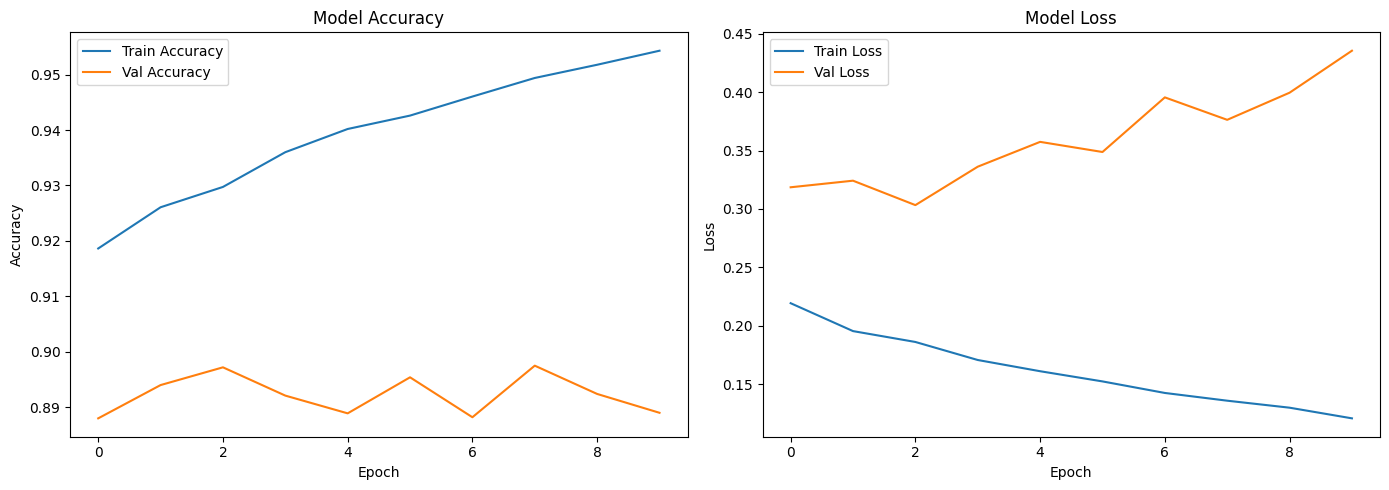

In [14]:
# Plot training history: accuracy and loss curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()